In [1]:
!pip install catboost xgboost lightgbm gradio

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 97.1/97.1 MB 46.3 MB/s  0:00:02


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm import tqdm
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

from sklearn.linear_model import LinearRegression , Lasso ,Ridge
from sklearn.neighbors import KNeighborsRegressor
from sklearn.svm import SVR
from sklearn.tree import DecisionTreeRegressor
from sklearn.experimental import enable_hist_gradient_boosting  # Needed for HistGB
from sklearn.ensemble import (RandomForestRegressor,ExtraTreesRegressor,BaggingRegressor,
                              AdaBoostRegressor ,GradientBoostingRegressor,HistGradientBoostingRegressor
                              , VotingRegressor,StackingRegressor)
#import xgboost as xgb
from xgboost import XGBRegressor
from catboost import CatBoostRegressor
#import lightgbm as lgb
from lightgbm import LGBMRegressor

/usr/local/lib/python3.13/dist-packages/sklearn/experimental/enable_hist_gradient_boosting.py:19: UserWarning: Since version 1.0, it is not needed to import enable_hist_gradient_boosting anymore. HistGradientBoostingClassifier and HistGradientBoostingRegressor are now stable and can be normally imported from sklearn.ensemble.
  warnings.warn(


In [3]:
df=pd.read_csv("cars_data.csv")

In [4]:
df.head()

,Brand,Year,Mileage,Engine_Size,Fuel_Type,Transmission,Previous_Owners,Price
0,Kia,2015,110373,2.5,Electric,Manual,2,3000
1,Mercedes,2010,186144,1.3,Electric,Manual,5,4844
2,Nissan,2018,29574,2.6,Petrol,Manual,1,6628
3,Kia,2010,139502,2.4,Diesel,Automatic,4,3000
4,BMW,2014,148748,3.5,Diesel,Manual,1,6451


In [5]:
df.shape

(1000, 8)

In [6]:
df.columns

Index(['Brand', 'Year', 'Mileage', 'Engine_Size', 'Fuel_Type', 'Transmission',
       'Previous_Owners', 'Price'],
      dtype='object')

In [7]:
df.describe()

,Year,Mileage,Engine_Size,Previous_Owners,Price
count,1000.000000,1000.000000,980.000000,1000.000000,1000.000000
mean,2016.300000,104551.675000,2.494592,3.062000,8473.646000
std,4.056162,56197.795061,0.865230,1.404325,6292.910864
min,2010.000000,5207.000000,1.000000,1.000000,3000.000000
25%,2013.000000,54239.250000,1.800000,2.000000,4069.500000
50%,2016.000000,105298.000000,2.500000,3.000000,6439.000000
75%,2020.000000,155468.250000,3.225000,4.000000,10905.500000
max,2023.000000,199812.000000,4.000000,5.000000,43994.000000


In [8]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 8 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Brand            1000 non-null   object 
 1   Year             1000 non-null   int64  
 2   Mileage          1000 non-null   int64  
 3   Engine_Size      980 non-null    float64
 4   Fuel_Type        1000 non-null   object 
 5   Transmission     1000 non-null   object 
 6   Previous_Owners  1000 non-null   int64  
 7   Price            1000 non-null   int64  
dtypes: float64(1), int64(4), object(3)
memory usage: 62.6+ KB


In [9]:
df.isnull().sum().sort_values(ascending=False).head(3)

,0
Engine_Size,20
Brand,0
Year,0


<Axes: xlabel='Engine_Size', ylabel='Count'>

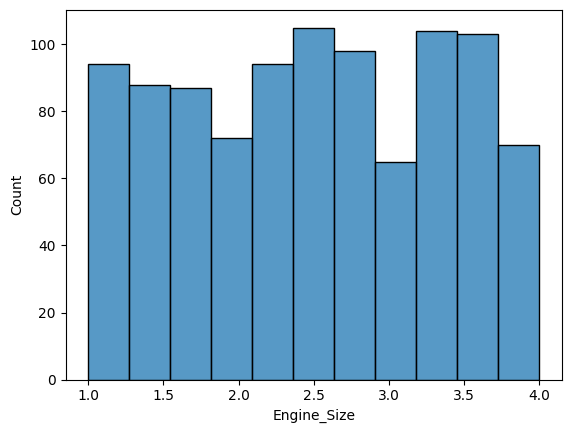

In [10]:
sns.histplot(data=df,x='Engine_Size')

In [11]:
from sklearn.impute import SimpleImputer

In [12]:
impute = SimpleImputer(missing_values=np.nan,strategy='mean')

In [13]:
"""impute.fit(df[['Engine_Size']])
df[['Engine_Size']] = impute.transform(df[['Engine_Size']])"""
#df['Engine_Size'].fillna(value=df['Engine_Size'].mean())

"impute.fit(df[['Engine_Size']])\ndf[['Engine_Size']] = impute.transform(df[['Engine_Size']])"

In [14]:
df[['Engine_Size']] = impute.fit_transform(df[['Engine_Size']])

In [15]:
df.isnull().sum().sum()

np.int64(0)

In [16]:
df.duplicated().sum()

np.int64(0)

In [17]:
df.drop_duplicates(inplace=True)

In [18]:
df.reset_index(drop=True,inplace=True)

In [19]:
df.head()

,Brand,Year,Mileage,Engine_Size,Fuel_Type,Transmission,Previous_Owners,Price
0,Kia,2015,110373,2.5,Electric,Manual,2,3000
1,Mercedes,2010,186144,1.3,Electric,Manual,5,4844
2,Nissan,2018,29574,2.6,Petrol,Manual,1,6628
3,Kia,2010,139502,2.4,Diesel,Automatic,4,3000
4,BMW,2014,148748,3.5,Diesel,Manual,1,6451


<Axes: xlabel='Transmission', ylabel='count'>

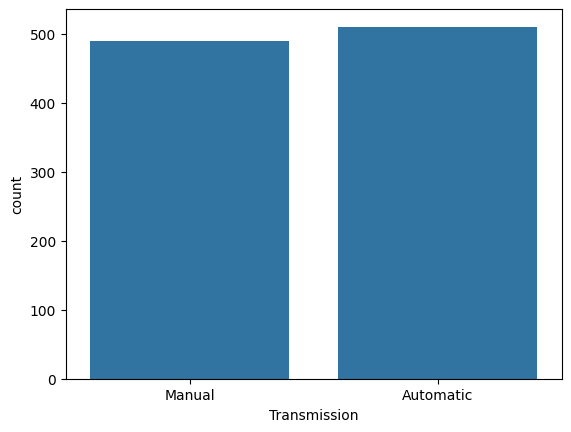

In [20]:
sns.countplot(x=df['Transmission'])

<Axes: xlabel='Transmission', ylabel='count'>

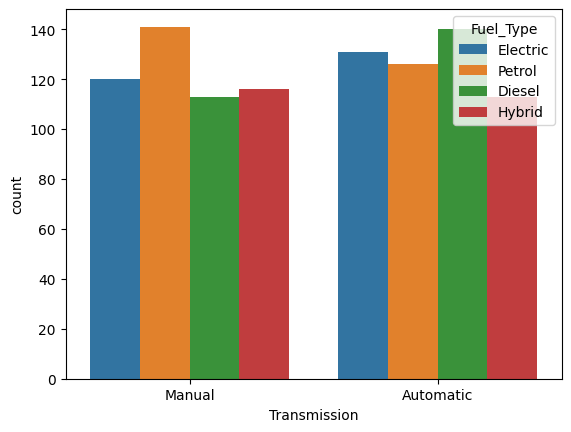

In [21]:
sns.countplot(x=df['Transmission'],hue=df['Fuel_Type'])

In [22]:
df.columns

Index(['Brand', 'Year', 'Mileage', 'Engine_Size', 'Fuel_Type', 'Transmission',
       'Previous_Owners', 'Price'],
      dtype='object')

<Axes: xlabel='Mileage', ylabel='Price'>

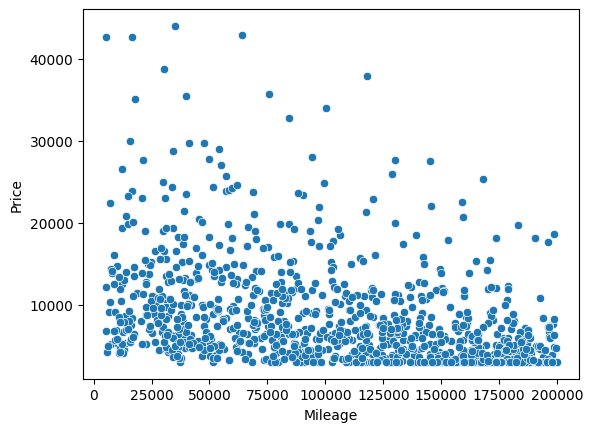

In [23]:
sns.scatterplot(data=df,x='Mileage',y='Price')

<Axes: xlabel='Mileage', ylabel='Price'>

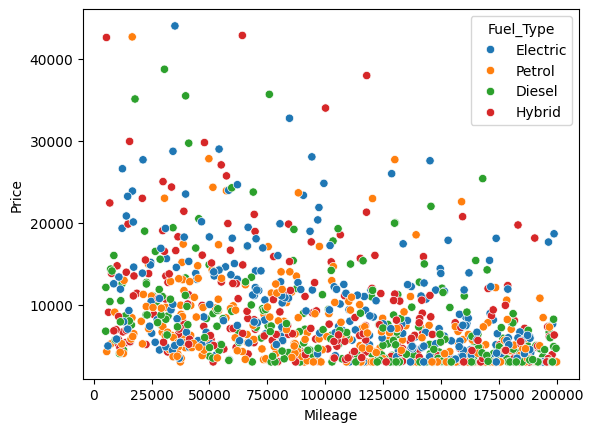

In [24]:
sns.scatterplot(data=df,x='Mileage',y='Price',hue='Fuel_Type')

<Axes: xlabel='Mileage', ylabel='Price'>

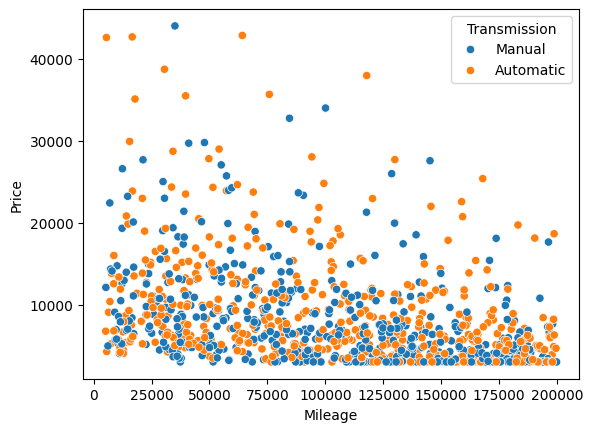

In [25]:
sns.scatterplot(data=df,x='Mileage',y='Price',hue='Transmission')

In [26]:
df.head()

,Brand,Year,Mileage,Engine_Size,Fuel_Type,Transmission,Previous_Owners,Price
0,Kia,2015,110373,2.5,Electric,Manual,2,3000
1,Mercedes,2010,186144,1.3,Electric,Manual,5,4844
2,Nissan,2018,29574,2.6,Petrol,Manual,1,6628
3,Kia,2010,139502,2.4,Diesel,Automatic,4,3000
4,BMW,2014,148748,3.5,Diesel,Manual,1,6451


<Axes: xlabel='Engine_Size', ylabel='Price'>

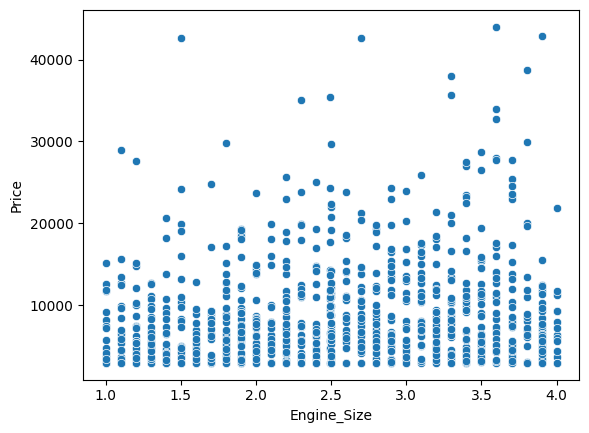

In [27]:
sns.scatterplot(data=df,x='Engine_Size',y='Price')

<Axes: xlabel='Mileage'>

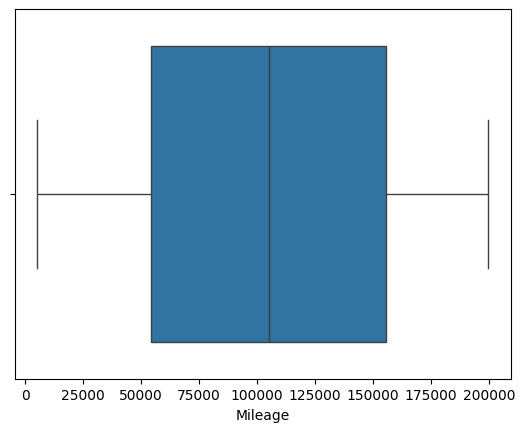

In [28]:
sns.boxplot(data=df,x='Mileage')

<Axes: >

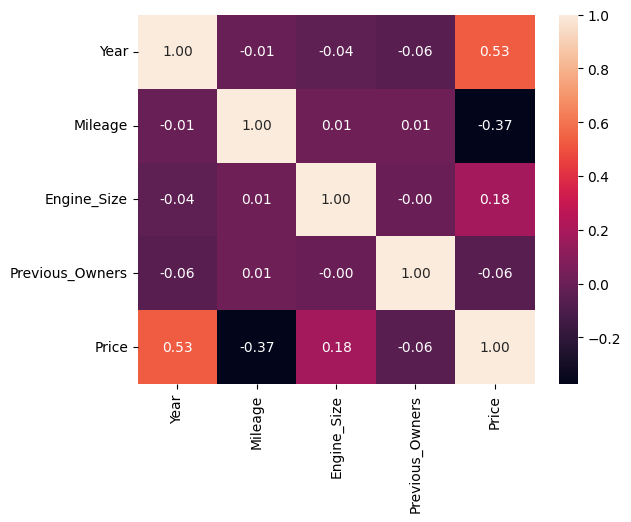

In [29]:
sns.heatmap(df.corr(numeric_only=True),annot=True,fmt='0.2f')

<Axes: xlabel='Year', ylabel='Price'>

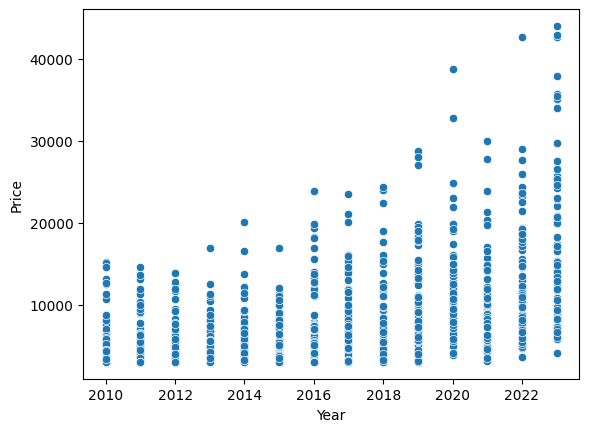

In [30]:
sns.scatterplot(data=df,x='Year',y='Price')

<Axes: xlabel='Year', ylabel='Price'>

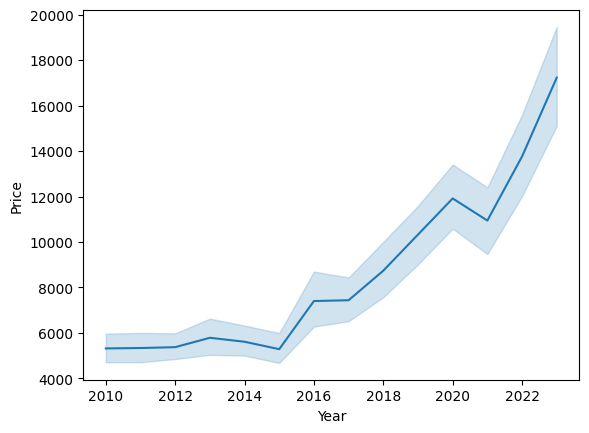

In [31]:
sns.lineplot(data=df,x='Year',y='Price')

<Axes: xlabel='Engine_Size', ylabel='Price'>

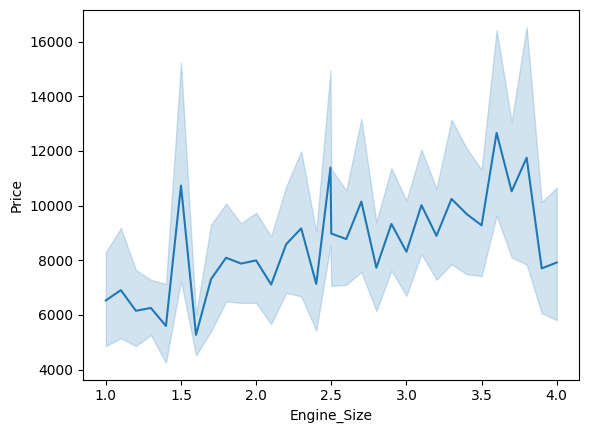

In [32]:
sns.lineplot(data=df,x='Engine_Size',y='Price')

<Axes: xlabel='Mileage', ylabel='Price'>

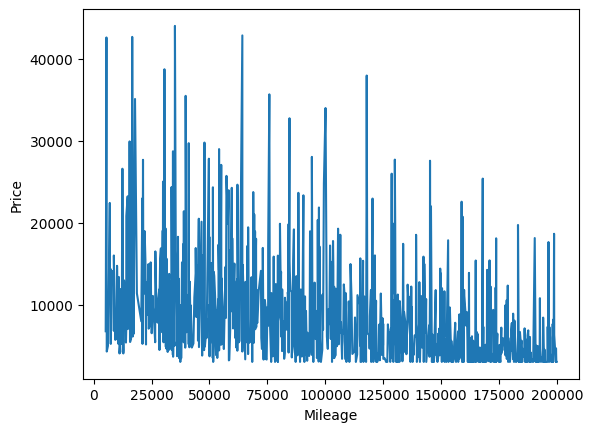

In [33]:
sns.lineplot(data=df,x='Mileage',y='Price')

In [34]:
df.head()

,Brand,Year,Mileage,Engine_Size,Fuel_Type,Transmission,Previous_Owners,Price
0,Kia,2015,110373,2.5,Electric,Manual,2,3000
1,Mercedes,2010,186144,1.3,Electric,Manual,5,4844
2,Nissan,2018,29574,2.6,Petrol,Manual,1,6628
3,Kia,2010,139502,2.4,Diesel,Automatic,4,3000
4,BMW,2014,148748,3.5,Diesel,Manual,1,6451


<Axes: xlabel='Previous_Owners', ylabel='Price'>

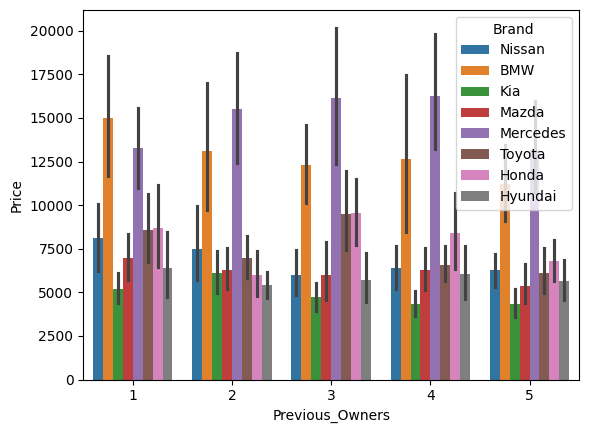

In [35]:
sns.barplot(data=df,x='Previous_Owners',y='Price',hue = 'Brand')

<Axes: xlabel='Brand', ylabel='Price'>

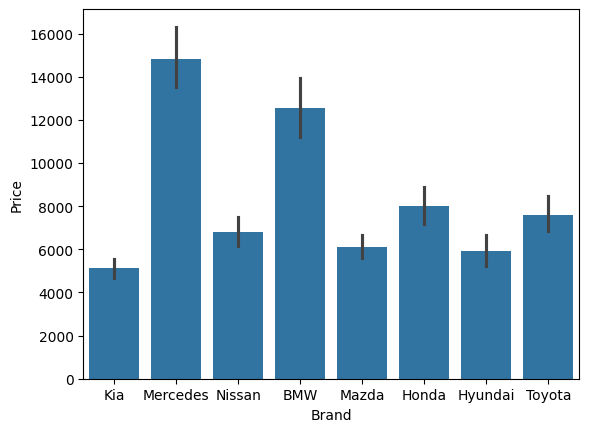

In [36]:
sns.barplot(data=df,x='Brand',y='Price')

<Axes: xlabel='Brand', ylabel='count'>

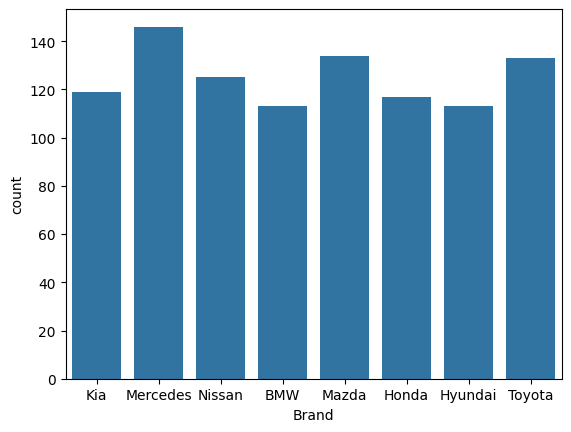

In [37]:
sns.countplot(x=df['Brand'])

<Axes: xlabel='Mileage', ylabel='Count'>

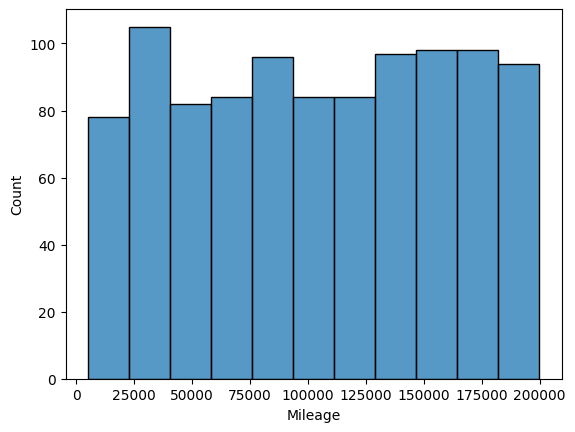

In [38]:
sns.histplot(x=df['Mileage'])

<Axes: xlabel='Price', ylabel='Count'>

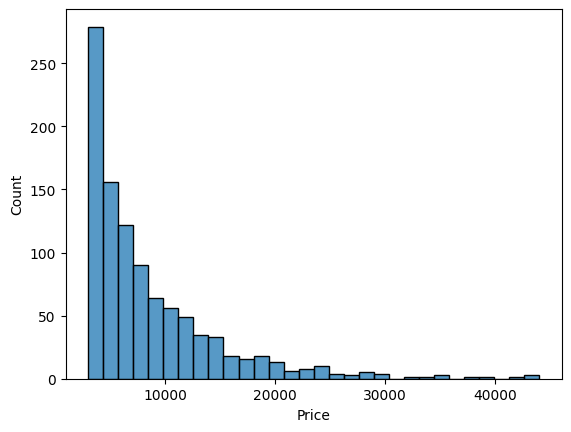

In [39]:
sns.histplot(x=df['Price'])

<Axes: xlabel='Price'>

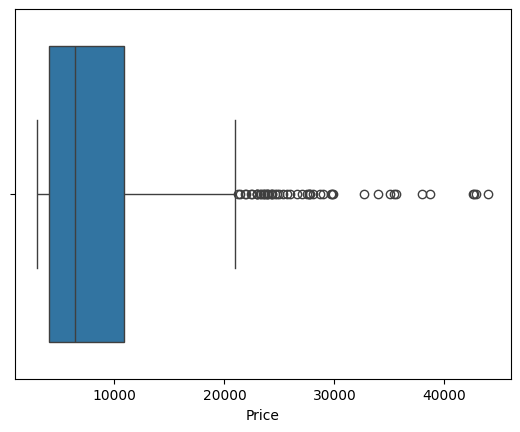

In [40]:
sns.boxplot(x=df['Price'])

In [41]:
df = df[df['Price']<40000]

<Axes: xlabel='Price'>

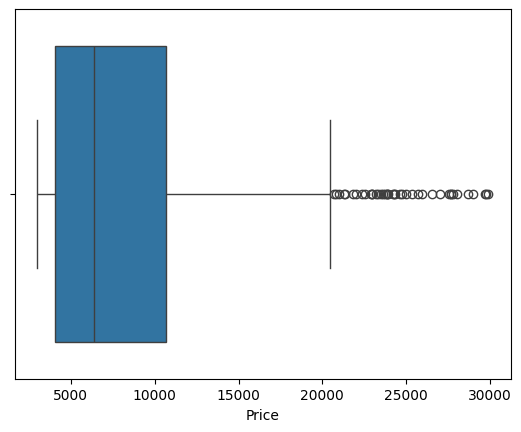

In [42]:
sns.boxplot(x=df[df['Price']<32000]['Price'])

In [43]:
df[df['Price']<32000]['Price'].shape

(989,)

In [44]:
df = df[df['Price']<32000]

In [45]:
df.shape

(989, 8)

In [46]:
df.reset_index(drop=True,inplace=True)

In [47]:
from sklearn.preprocessing import LabelEncoder,OneHotEncoder

In [48]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 989 entries, 0 to 988
Data columns (total 8 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Brand            989 non-null    object 
 1   Year             989 non-null    int64  
 2   Mileage          989 non-null    int64  
 3   Engine_Size      989 non-null    float64
 4   Fuel_Type        989 non-null    object 
 5   Transmission     989 non-null    object 
 6   Previous_Owners  989 non-null    int64  
 7   Price            989 non-null    int64  
dtypes: float64(1), int64(4), object(3)
memory usage: 61.9+ KB


In [49]:
df['Brand'].nunique()

8

In [50]:
df['Fuel_Type'].unique()

array(['Electric', 'Petrol', 'Diesel', 'Hybrid'], dtype=object)

In [51]:
df['Transmission'].unique()

array(['Manual', 'Automatic'], dtype=object)

In [52]:
onehot = OneHotEncoder()

In [53]:
New = onehot.fit_transform(df[['Brand']]).toarray()
New

array([[0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 1., 0., 0.],
       [0., 0., 0., ..., 0., 1., 0.],
       ...,
       [0., 0., 0., ..., 1., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.],
       [1., 0., 0., ..., 0., 0., 0.]], shape=(989, 8))

In [54]:
onehot.categories_[0]

array(['BMW', 'Honda', 'Hyundai', 'Kia', 'Mazda', 'Mercedes', 'Nissan',
       'Toyota'], dtype=object)

In [55]:
for index,col in enumerate(onehot.categories_[0]):
    df[col]=New[:,index]

In [56]:
df.head()

,Brand,Year,Mileage,Engine_Size,Fuel_Type,Transmission,Previous_Owners,Price,BMW,Honda,Hyundai,Kia,Mazda,Mercedes,Nissan,Toyota
0,Kia,2015,110373,2.5,Electric,Manual,2,3000,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0
1,Mercedes,2010,186144,1.3,Electric,Manual,5,4844,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
2,Nissan,2018,29574,2.6,Petrol,Manual,1,6628,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
3,Kia,2010,139502,2.4,Diesel,Automatic,4,3000,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0
4,BMW,2014,148748,3.5,Diesel,Manual,1,6451,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [57]:
df.drop('Brand',axis = 1 ,inplace=True)

In [58]:
New1 = onehot.fit_transform(df[['Fuel_Type']]).toarray()
New1

array([[0., 1., 0., 0.],
       [0., 1., 0., 0.],
       [0., 0., 0., 1.],
       ...,
       [0., 0., 1., 0.],
       [1., 0., 0., 0.],
       [0., 0., 0., 1.]], shape=(989, 4))

In [59]:
New1=pd.DataFrame(New1,columns=onehot.categories_[0])
New1.head()

,Diesel,Electric,Hybrid,Petrol
0,0.0,1.0,0.0,0.0
1,0.0,1.0,0.0,0.0
2,0.0,0.0,0.0,1.0
3,1.0,0.0,0.0,0.0
4,1.0,0.0,0.0,0.0


In [60]:
df=pd.concat([df,New1],axis=1)

In [61]:
df.head()

,Year,Mileage,Engine_Size,Fuel_Type,Transmission,Previous_Owners,Price,BMW,Honda,Hyundai,Kia,Mazda,Mercedes,Nissan,Toyota,Diesel,Electric,Hybrid,Petrol
0,2015,110373,2.5,Electric,Manual,2,3000,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
1,2010,186144,1.3,Electric,Manual,5,4844,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0
2,2018,29574,2.6,Petrol,Manual,1,6628,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0
3,2010,139502,2.4,Diesel,Automatic,4,3000,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0
4,2014,148748,3.5,Diesel,Manual,1,6451,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0


In [62]:
df.drop('Fuel_Type',axis=1,inplace=True)

In [63]:
lable_encoding =LabelEncoder()

In [64]:
df['Transmission'] =lable_encoding.fit_transform(df['Transmission'])

In [65]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 989 entries, 0 to 988
Data columns (total 18 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Year             989 non-null    int64  
 1   Mileage          989 non-null    int64  
 2   Engine_Size      989 non-null    float64
 3   Transmission     989 non-null    int64  
 4   Previous_Owners  989 non-null    int64  
 5   Price            989 non-null    int64  
 6   BMW              989 non-null    float64
 7   Honda            989 non-null    float64
 8   Hyundai          989 non-null    float64
 9   Kia              989 non-null    float64
 10  Mazda            989 non-null    float64
 11  Mercedes         989 non-null    float64
 12  Nissan           989 non-null    float64
 13  Toyota           989 non-null    float64
 14  Diesel           989 non-null    float64
 15  Electric         989 non-null    float64
 16  Hybrid           989 non-null    float64
 17  Petrol          

In [66]:
df.head()

,Year,Mileage,Engine_Size,Transmission,Previous_Owners,Price,BMW,Honda,Hyundai,Kia,Mazda,Mercedes,Nissan,Toyota,Diesel,Electric,Hybrid,Petrol
0,2015,110373,2.5,1,2,3000,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
1,2010,186144,1.3,1,5,4844,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0
2,2018,29574,2.6,1,1,6628,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0
3,2010,139502,2.4,0,4,3000,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0
4,2014,148748,3.5,1,1,6451,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0


In [67]:
y=df['Price']

In [68]:
X=df.drop('Price',axis=1)

In [69]:
from sklearn.model_selection import train_test_split

In [70]:
X_train,X_test,y_train,y_test = train_test_split(X,y,test_size=0.2,random_state=42,shuffle=True)

In [71]:
from sklearn.preprocessing import MinMaxScaler,StandardScaler

In [72]:
scaler = MinMaxScaler()

In [73]:
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

In [74]:
models ={
    "Linear Regression":LinearRegression(),
    "Lasso":Lasso(),
    "Ridge":Ridge(),
    "KNN":KNeighborsRegressor(n_neighbors=5,metric='minkowski',p=1), #  minkowski , euclidean , manhattan
    "SVM":SVR(kernel='linear', C=100, gamma=1), # kernel='rbf' / kernel='poly', degree=4 / kernel='sigmoid
    "Decision Tree":DecisionTreeRegressor(criterion='squared_error',max_depth=10), #{"squared_error", "friedman_mse", "absolute_error", "poisson"}
    "Random Forest":RandomForestRegressor(n_estimators=50,criterion='squared_error',max_depth=10), #{"squared_error", "friedman_mse", "absolute_error", "poisson"}
    "ExtraTrees": ExtraTreesRegressor(n_estimators=100, random_state=42),
    "Bagging": BaggingRegressor(estimator=DecisionTreeRegressor(criterion='squared_error',max_depth=10),n_estimators=50, random_state=42),
    "AdaBoost": AdaBoostRegressor(n_estimators=15, random_state=42),
    "GradientBoosting": GradientBoostingRegressor(n_estimators=100, learning_rate=0.1, random_state=42),
    "HistGradientBoosting": HistGradientBoostingRegressor(max_iter=100, learning_rate=0.1, random_state=42),
    "XGBoost": XGBRegressor(n_estimators=100, learning_rate=0.1, random_state=42, verbosity=0),
    "CatBoost": CatBoostRegressor(verbose=0, iterations=100, learning_rate=0.1, random_state=42),
    "LightGBM": LGBMRegressor(n_estimators=100, learning_rate=0.1, random_state=42)
}

In [75]:
def regression_metrics(model, X, y_actual):
    y_pred = model.predict(X)
    MAE = mean_absolute_error(y_actual, y_pred)
    MSE = mean_squared_error(y_actual, y_pred)
    RMSE = np.sqrt(MSE)
    R2 = r2_score(y_actual, y_pred)
    return MAE, MSE, RMSE, R2

  0%|          | 0/15 [00:00<?, ?it/s]

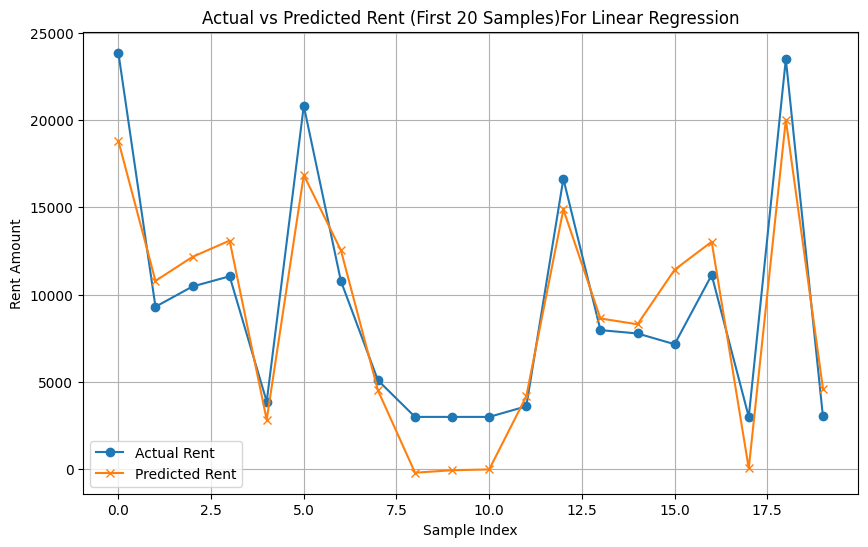

  7%|▋         | 1/15 [00:00<00:09,  1.42it/s]

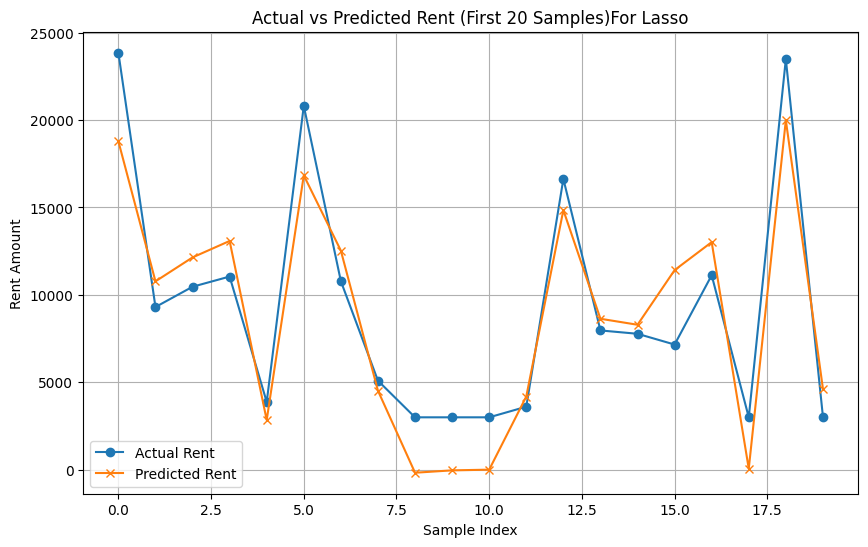

 13%|█▎        | 2/15 [00:01<00:06,  1.93it/s]

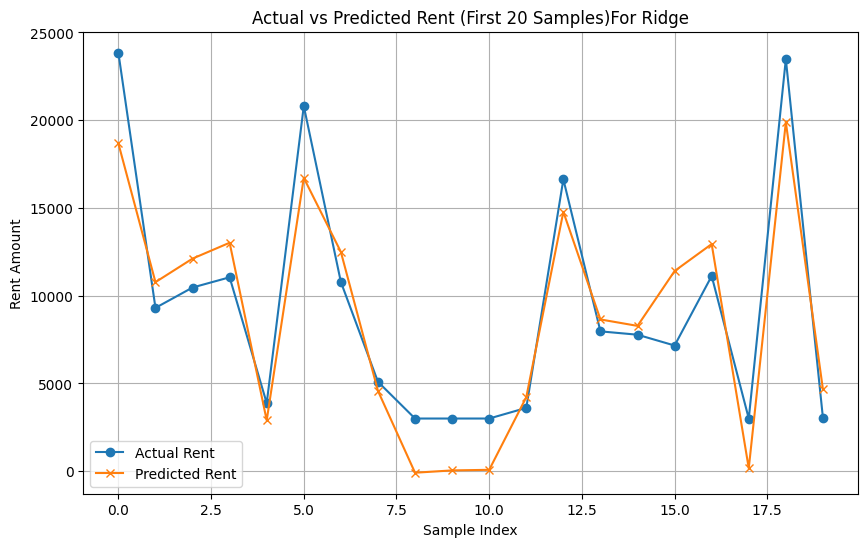

 20%|██        | 3/15 [00:01<00:05,  2.03it/s]

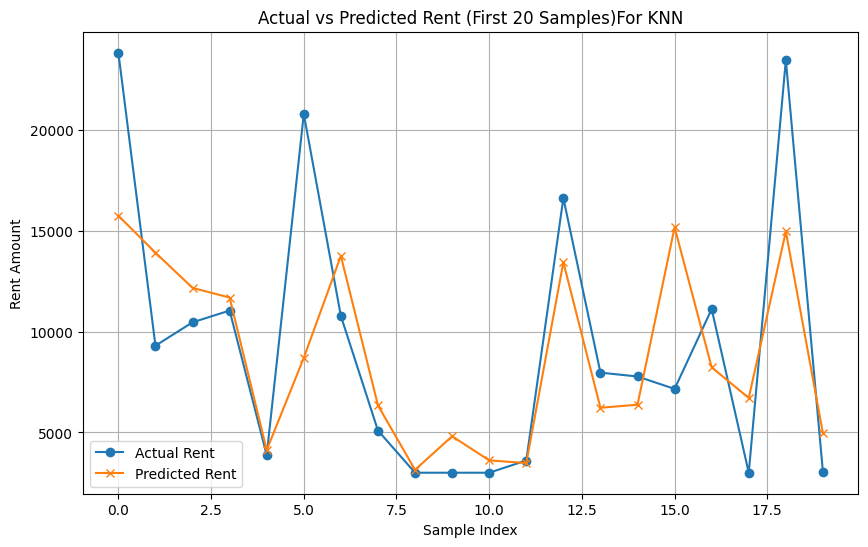

 27%|██▋       | 4/15 [00:02<00:06,  1.74it/s]

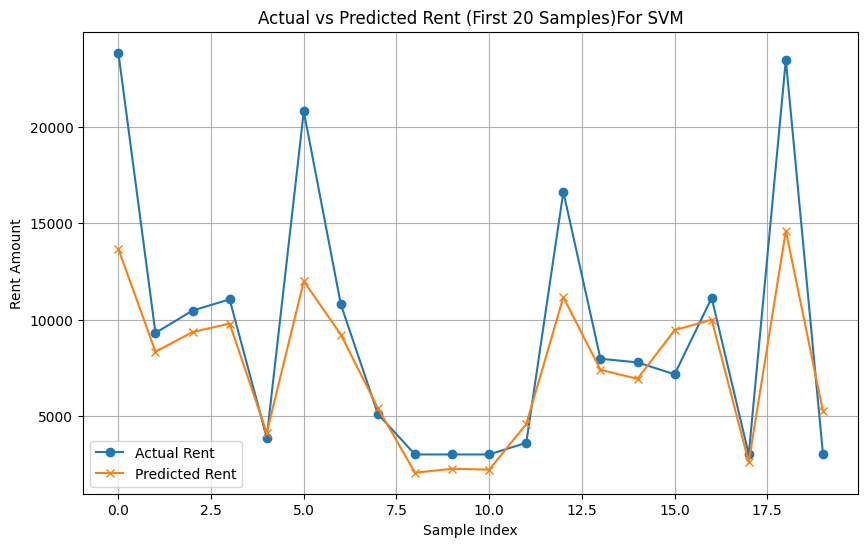

 33%|███▎      | 5/15 [00:02<00:05,  1.68it/s]

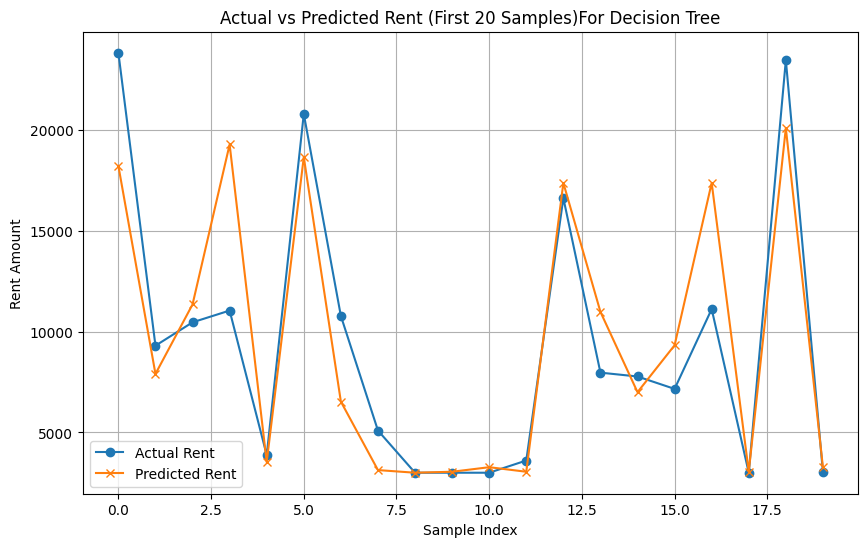

 40%|████      | 6/15 [00:03<00:05,  1.74it/s]

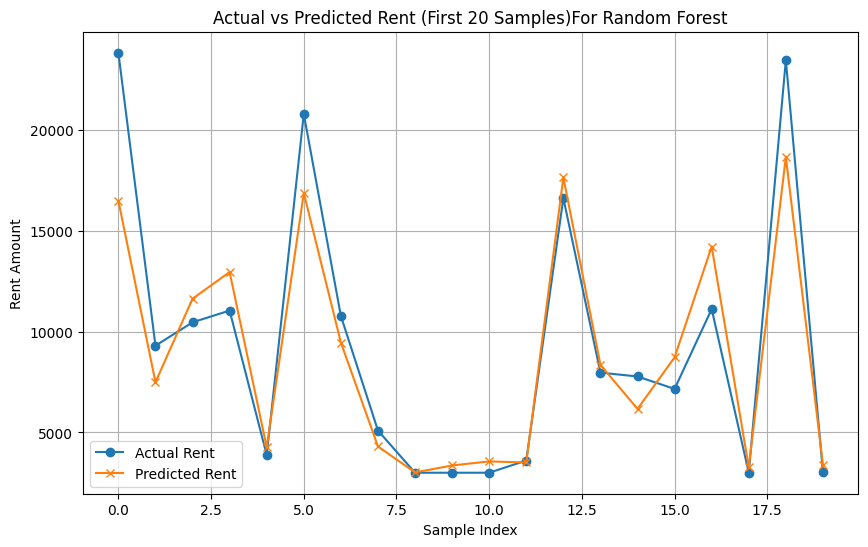

 47%|████▋     | 7/15 [00:04<00:05,  1.42it/s]

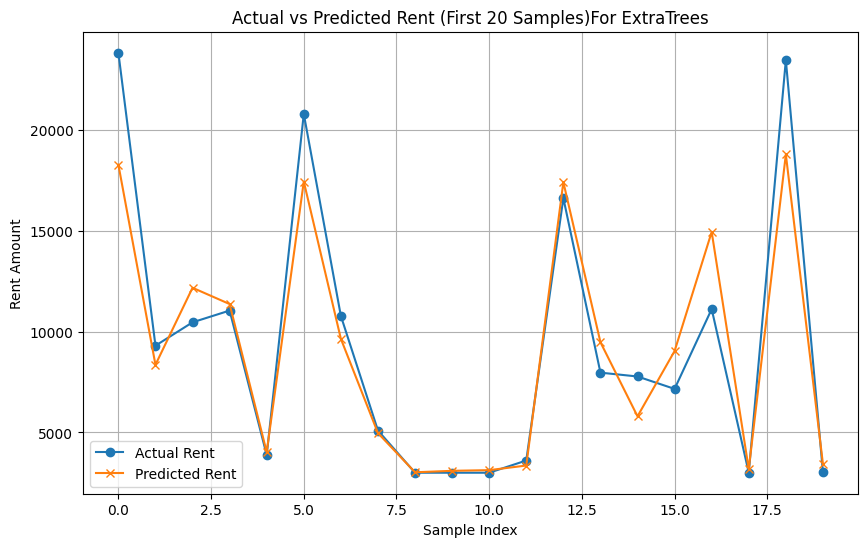

 53%|█████▎    | 8/15 [00:07<00:09,  1.40s/it]

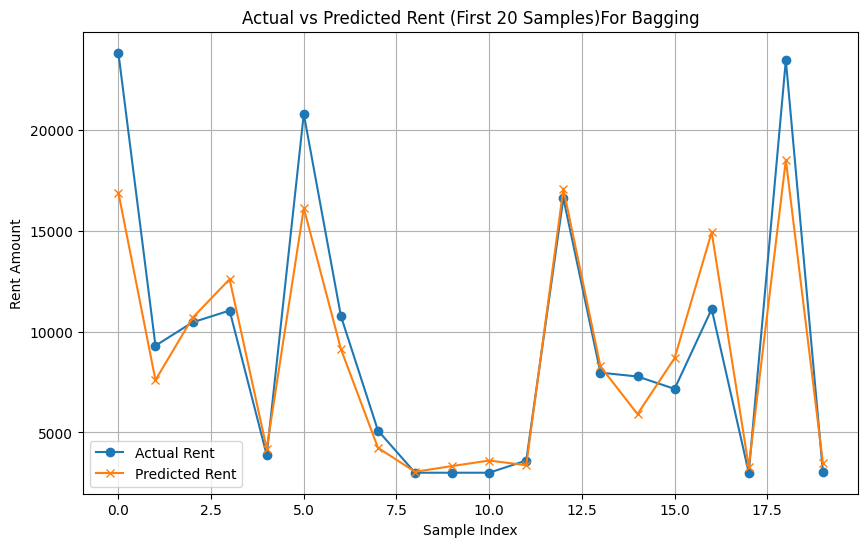

 60%|██████    | 9/15 [00:08<00:08,  1.48s/it]

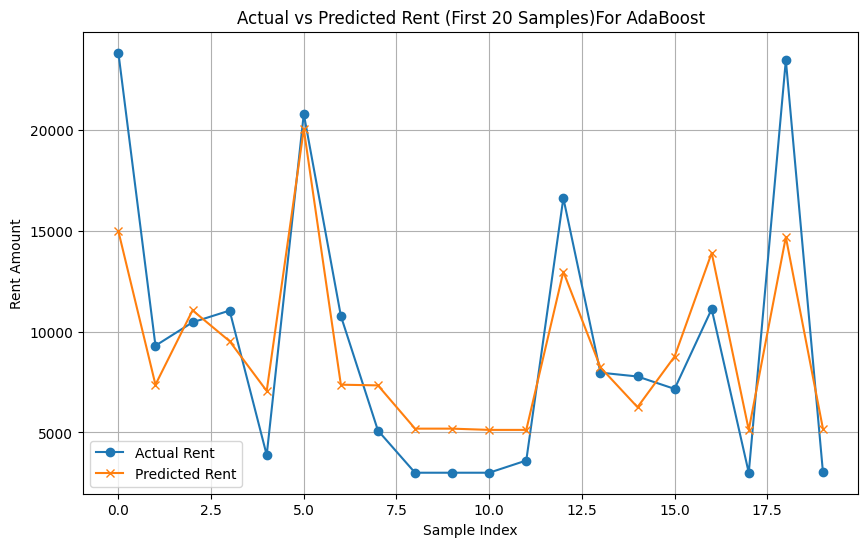

 67%|██████▋   | 10/15 [00:09<00:06,  1.22s/it]

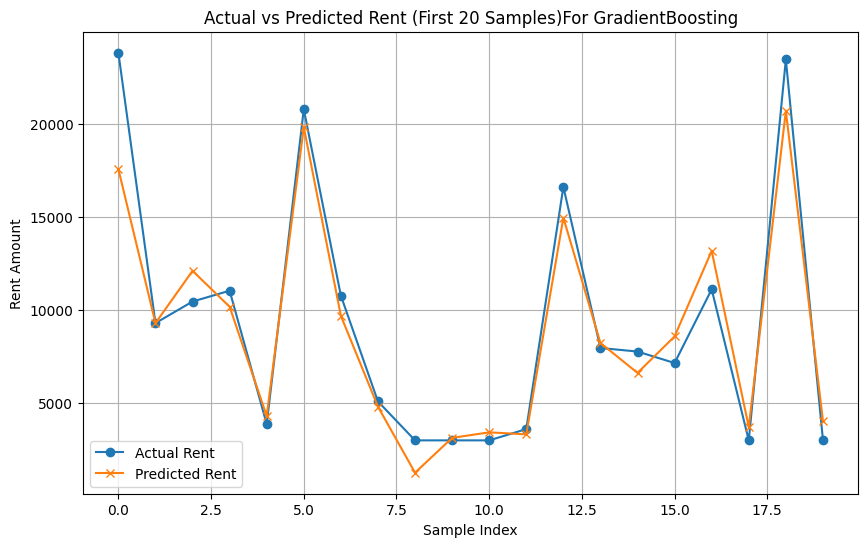

 73%|███████▎  | 11/15 [00:10<00:04,  1.10s/it]

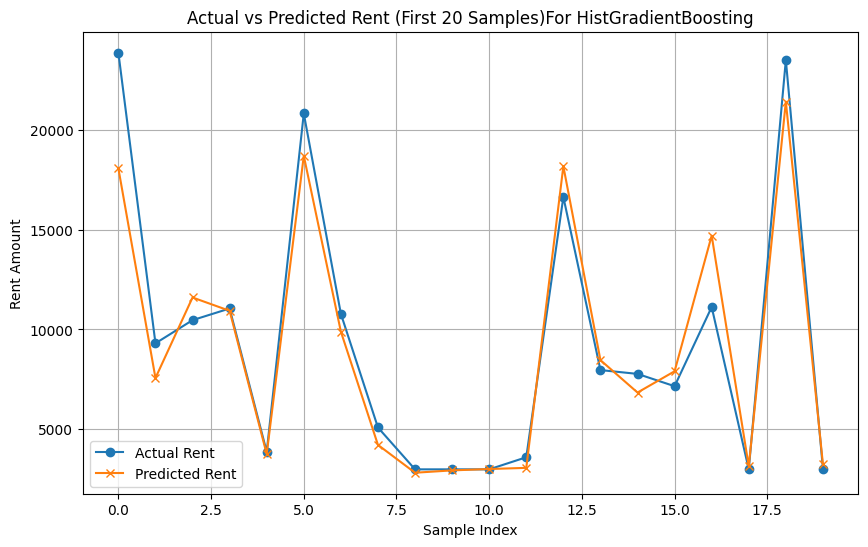

 80%|████████  | 12/15 [00:12<00:03,  1.27s/it]

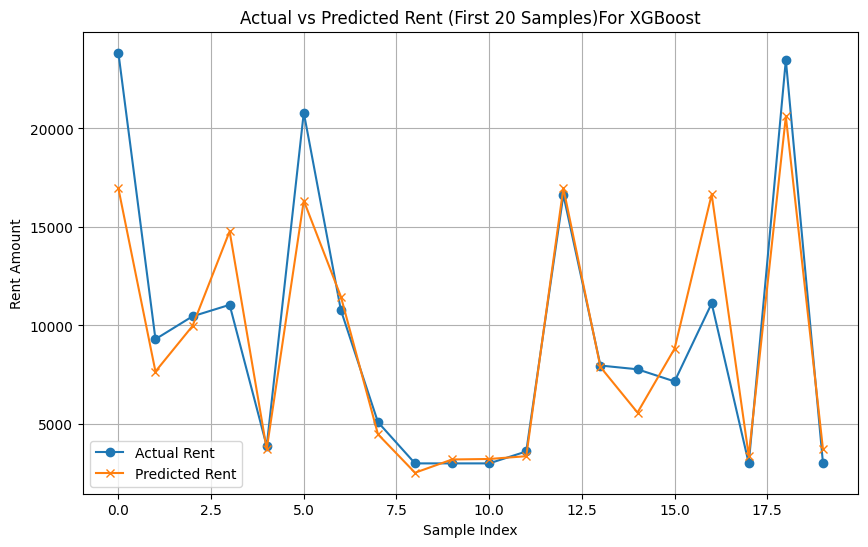

 87%|████████▋ | 13/15 [00:13<00:02,  1.24s/it]

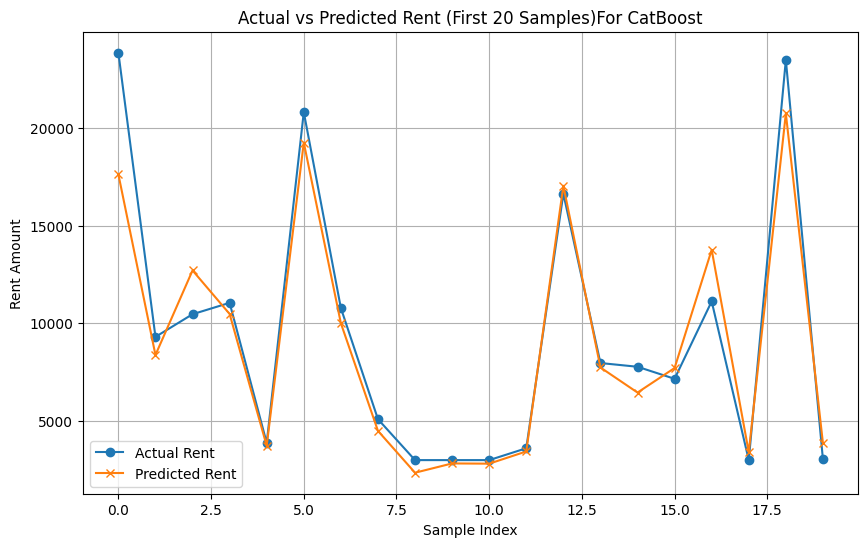

 93%|█████████▎| 14/15 [00:14<00:01,  1.13s/it]/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(


[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.006188 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 332
[LightGBM] [Info] Number of data points in the train set: 791, number of used features: 17
[LightGBM] [Info] Start training from score 8074.462705
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain,

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(


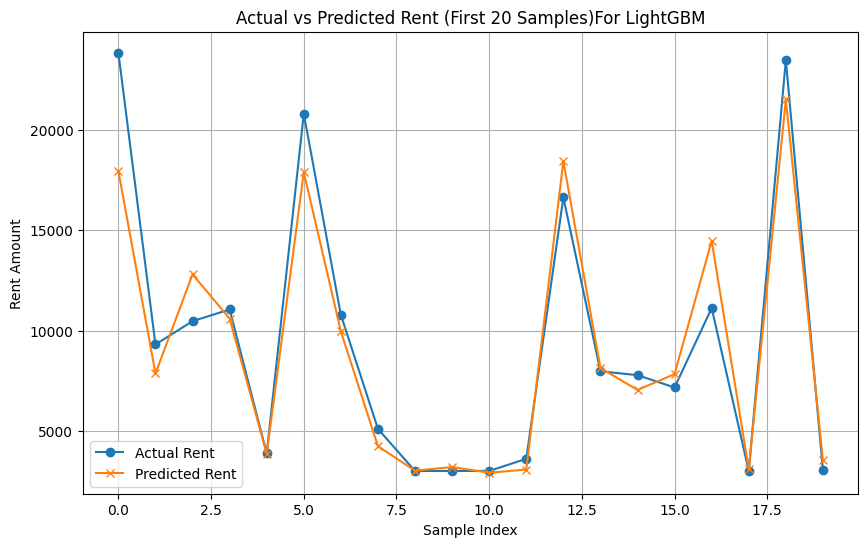

100%|██████████| 15/15 [00:14<00:00,  1.01it/s]


In [76]:
errors={}
for model_name , model in tqdm(models.items()):
    model.fit(X_train,y_train)
    MAE_Train, MSE_Train, RMSE_Train, R_Train = regression_metrics(model, X_train, y_train)
    MAE_Test, MSE_Test, RMSE_Test, R_Test = regression_metrics(model, X_test, y_test)

    errors[model_name] = {
        "MAE Train":MAE_Train,
        "MAE Test":MAE_Test,
        "MSE Train":MSE_Train,
        "MSE Test":MSE_Test,
        "RMSE Train":RMSE_Train,
        "RMSE Test":RMSE_Test,
        "R2 Train":R_Train,
        "R2 Test":R_Test
    }

    #Plotting Actual vs Predicted for first 20 test samples
    y_test_plot = y_test.values[:20]
    y_pred_plot = model.predict(X_test[:20])

    plt.figure(figsize=(10,6))
    plt.plot(range(20), y_test_plot, label='Actual Rent', marker='o')
    plt.plot(range(20), y_pred_plot, label='Predicted Rent', marker='x')
    plt.xlabel('Sample Index')
    plt.ylabel('Rent Amount')
    plt.title('Actual vs Predicted Rent (First 20 Samples)For '+ model_name)
    plt.legend()
    plt.grid()
    plt.show()

In [77]:
clf1 = LinearRegression()
clf2 = RandomForestRegressor(n_estimators=50, random_state=1)
clf3 = DecisionTreeRegressor(random_state=1)

# Voting Regressors (only averaging is supported)
model1 = VotingRegressor(estimators=[
    ('lr', clf1), ('rf', clf2), ('dt', clf3)
])

model2 = VotingRegressor(estimators=[
    ('lr', clf1), ('rf', clf2), ('dt', clf3)
])

# Weighted averaging
model3 = VotingRegressor(estimators=[
    ('lr', clf1), ('rf', clf2), ('dt', clf3)
], weights=[2, 1, 2])

# Fit models
model1.fit(X_train, y_train)
model2.fit(X_train, y_train)
model3.fit(X_train, y_train)


# Model 1
MAE_Train, MSE_Train, RMSE_Train, R2_Train = regression_metrics(model1, X_train, y_train)
MAE_test, MSE_test, RMSE_test, R2_Test = regression_metrics(model1, X_test, y_test)

errors["Voting"] = {
        "MAE Train":MAE_Train,
        "MAE Test":MAE_Test,
        "MSE Train":MSE_Train,
        "MSE Test":MSE_Test,
        "RMSE Train":RMSE_Train,
        "RMSE Test":RMSE_Test,
        "R2 Train":R2_Train,
        "R2 Test":R2_Test
    }

# Model 2
MAE_Train, MSE_Train, RMSE_Train, R2_Train = regression_metrics(model2, X_train, y_train)
MAE_test, MSE_test, RMSE_test, R2_Test = regression_metrics(model2, X_test, y_test)
errors["Simple Voting"] = {
        "MAE Train":MAE_Train,
        "MAE Test":MAE_Test,
        "MSE Train":MSE_Train,
        "MSE Test":MSE_Test,
        "RMSE Train":RMSE_Train,
        "RMSE Test":RMSE_Test,
        "R2 Train":R2_Train,
        "R2 Test":R2_Test
    }

# Model 3
MAE_Train, MSE_Train, RMSE_Train, R2_Train = regression_metrics(model3, X_train, y_train)
MAE_test, MSE_test, RMSE_test, R2_Test = regression_metrics(model3, X_test, y_test)
errors["Weighted Voting"] = {
        "MAE Train":MAE_Train,
        "MAE Test":MAE_Test,
        "MSE Train":MSE_Train,
        "MSE Test":MSE_Test,
        "RMSE Train":RMSE_Train,
        "RMSE Test":RMSE_Test,
        "R2 Train":R2_Train,
        "R2 Test":R2_Test
    }


In [78]:
regressors = [
    ('rf', RandomForestRegressor(n_estimators=50, random_state=42)),
    ('gb', GradientBoostingRegressor(n_estimators=50, learning_rate=0.1, random_state=42)),
    ('cat', CatBoostRegressor(iterations=50, learning_rate=0.1, verbose=0)),
    ('lgb', LGBMRegressor(n_estimators=50, learning_rate=0.1, random_state=42))
]

# -----------------------------
# Meta-model
# -----------------------------
meta_regressor = XGBRegressor()

# -----------------------------
# Stacking Models
# -----------------------------
stacking_regressor = StackingRegressor(
    estimators=regressors,
    final_estimator=meta_regressor,
    cv=5,
    passthrough=True,
    n_jobs=-1
)


stacking_regressor.fit(X_train, y_train)
MAE_Train, MSE_Train, RMSE_Train, R2_Train = regression_metrics(stacking_regressor, X_train, y_train)
MAE_test, MSE_test, RMSE_test, R2_Test = regression_metrics(stacking_regressor, X_test, y_test)
errors["Stacking"] = {
        "MAE Train":MAE_Train,
        "MAE Test":MAE_Test,
        "MSE Train":MSE_Train,
        "MSE Test":MSE_Test,
        "RMSE Train":RMSE_Train,
        "RMSE Test":RMSE_Test,
        "R2 Train":R2_Train,
        "R2 Test":R2_Test
    }

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(


In [79]:
errors_df = pd.DataFrame(errors).T.sort_values(by="R2 Test",ascending=False)

In [80]:
errors_df

,MAE Train,MAE Test,MSE Train,MSE Test,RMSE Train,RMSE Test,R2 Train,R2 Test
CatBoost,644.363960,1107.532939,7.699931e+05,3.168988e+06,877.492486,1780.165142,0.973720,0.900226
HistGradientBoosting,508.313012,1185.757281,5.707946e+05,3.398682e+06,755.509523,1843.551378,0.980518,0.892994
LightGBM,519.221485,1182.899906,5.891951e+05,3.471860e+06,767.590424,1863.292656,0.979890,0.890690
Stacking,560.716980,1182.899906,8.526114e+05,3.471860e+06,923.369577,1863.292656,0.970900,0.881376
GradientBoosting,807.313062,1264.471673,1.165344e+06,3.932432e+06,1079.510919,1983.036057,0.960226,0.876189
ExtraTrees,0.000000,1277.039293,0.000000e+00,4.288371e+06,0.000000,2070.838226,1.000000,0.864982
XGBoost,194.448303,1363.151855,6.722423e+04,5.213688e+06,259.276367,2283.350280,0.997706,0.835849
Simple Voting,719.769002,1182.899906,9.586351e+05,3.471860e+06,979.099139,1863.292656,0.967281,0.822027
Voting,719.769002,1182.899906,9.586351e+05,3.471860e+06,979.099139,1863.292656,0.967281,0.822027
Weighted Voting,790.674261,1182.899906,1.132769e+06,3.471860e+06,1064.316127,1863.292656,0.961338,0.816135


<Axes: >

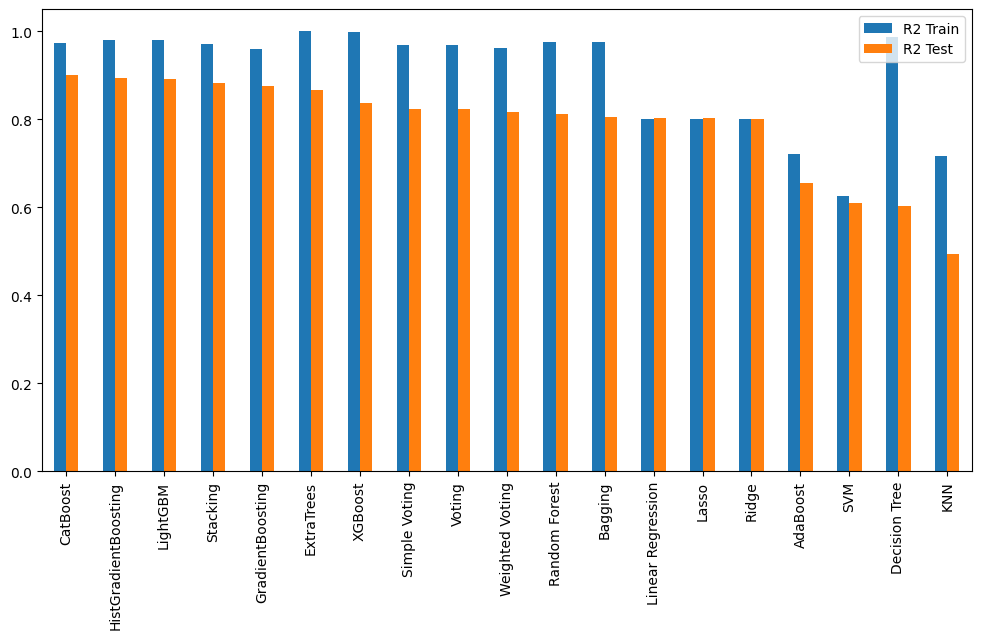

In [81]:
errors_df[["R2 Train", "R2 Test"]].plot.bar(figsize=(12,6))

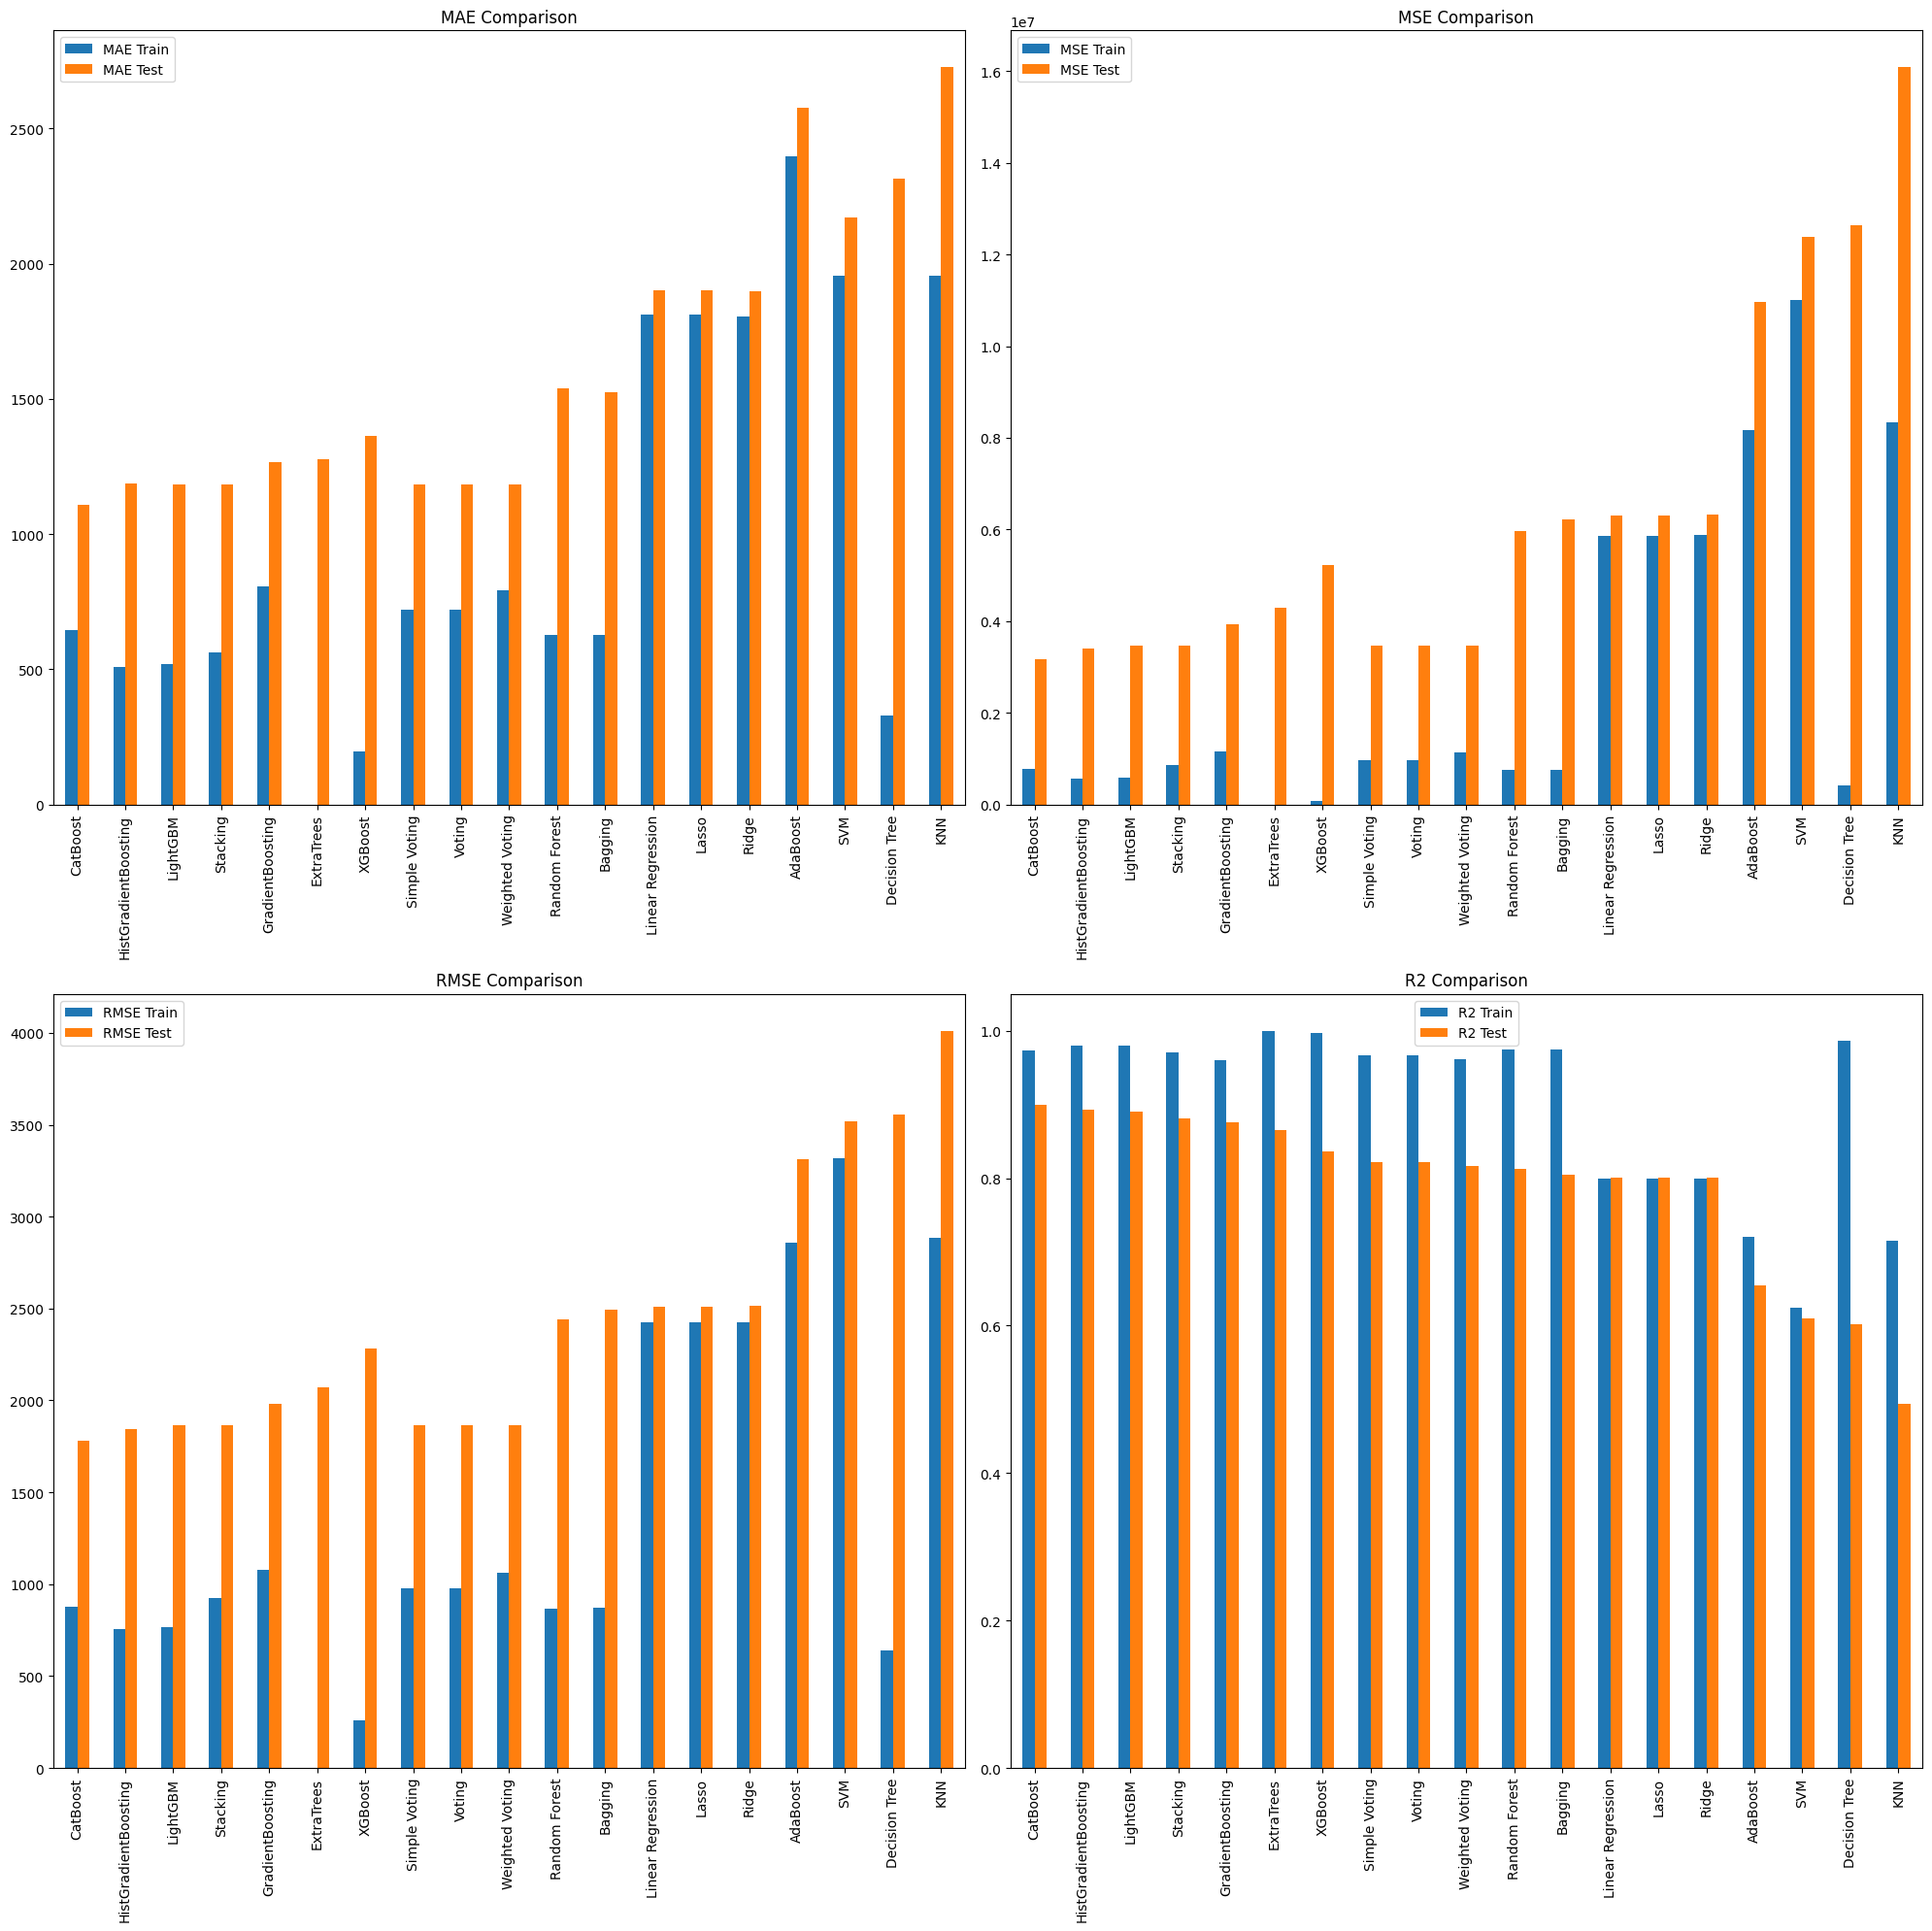

In [82]:
cols = [
    ['MAE Train', 'MAE Test'],
    ['MSE Train', 'MSE Test'],
    ['RMSE Train', 'RMSE Test'],
    ['R2 Train', 'R2 Test']
]

plt.figure(figsize=(20,20))

for i, col in enumerate(cols):
    ax = plt.subplot(2, 2, i+1)
    errors_df[col].plot.bar(ax=ax)
    ax.set_title(col[0].split(" ")[0] + ' Comparison')

plt.tight_layout()
plt.show()